<a href="https://colab.research.google.com/github/Rosanna-csr/Fitness-AQA/blob/patch-1/%E6%97%A5%E6%9C%AC%E4%BA%A4%E9%80%9A.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 統合パイプライン: 実写真での推論と論文用図の作成

In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)
import os

S2TLD_ROOT = '/content/drive/MyDrive/S2TLD'
CKPT_ROOT  = f'{S2TLD_ROOT}/checkpoints_v2'
PHOTO_DIR  = f'{S2TLD_ROOT}/my_photos'
OUTPUT_DIR = f'{S2TLD_ROOT}/my_photos_result'
os.makedirs(PHOTO_DIR,  exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)

YOLO_MODEL = f'{CKPT_ROOT}/pattern_B/stage1_pattern_B/weights/best.pt'
EFF_MODEL  = f'{CKPT_ROOT}/stage2_best.pt'

print(f'写真フォルダ : {PHOTO_DIR}')
print(f'出力フォルダ : {OUTPUT_DIR}')
print(f'YOLOモデル   : {os.path.exists(YOLO_MODEL)}')
print(f'EfficientNet : {os.path.exists(EFF_MODEL)}')


Mounted at /content/drive
写真フォルダ : /content/drive/MyDrive/S2TLD/my_photos
出力フォルダ : /content/drive/MyDrive/S2TLD/my_photos_result
YOLOモデル   : True
EfficientNet : True


### 检查模型文件路径
运行以下代码，查看 `CKPT_ROOT` (即 `/content/drive/MyDrive/S2TLD/checkpoints_v2`) 文件夹下的内容，以确认 `best.pt` 和 `stage2_best.pt` 文件的准确位置。请注意文件夹名称和文件名的拼写及大小写。

In [ ]:
import os

# 重新定义 S2TLD_ROOT 和 CKPT_ROOT，以便此单元格可以独立运行
S2TLD_ROOT = '/content/drive/MyDrive/S2TLD'
CKPT_ROOT  = f'{S2TLD_ROOT}/checkpoints_v2'

print(f'Listing contents of {CKPT_ROOT}:')

if os.path.exists(CKPT_ROOT):
    for root, dirs, files in os.walk(CKPT_ROOT):
        level = root.replace(CKPT_ROOT, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        for f in files:
            print(f'{subindent}{f}')
else:
    print(f'Error: The directory {CKPT_ROOT} does not exist. Please ensure S2TLD_ROOT is correct.')

# 请根据以上输出，修改 JS2oFQlXiwXA 单元格中的 YOLO_MODEL 和 EFF_MODEL 变量，使其指向正确的路径。

Listing contents of /content/drive/MyDrive/S2TLD/checkpoints_v2:
Error: The directory /content/drive/MyDrive/S2TLD/checkpoints_v2 does not exist. Please ensure S2TLD_ROOT is correct.


### 检查 Google Drive 根目录内容
运行以下代码，查看您 Google Drive 根目录 (`/content/drive/MyDrive`) 的内容。请务必仔细查找您的 `S2TLD` 文件夹，并确认其内部 `checkpoints_v2` 文件夹的准确路径。


In [ ]:
import os

drive_root = '/content/drive/MyDrive'

print(f'Listing contents of {drive_root}:')

if os.path.exists(drive_root):
    # Limit the depth to avoid listing too many files, focus on top-level structure
    for root, dirs, files in os.walk(drive_root):
        # Only list direct children of MyDrive and the next level down
        level = root.replace(drive_root, '').count(os.sep)
        if level > 2:  # Adjust this number to control depth. 0 for MyDrive, 1 for immediate subfolders, etc.
            continue

        indent = ' ' * 4 * (level)
        print(f'{indent}{os.path.basename(root)}/')
        subindent = ' ' * 4 * (level + 1)
        for d in dirs:
            print(f'{subindent}{d}/')
        for f in files:
            print(f'{subindent}{f}')
else:
    print(f'Error: The directory {drive_root} does not exist. Please ensure Google Drive is mounted correctly.')

# 请根据以上输出，修改 JS2oFQlXiwXA 单元格中的 S2TLD_ROOT, YOLO_MODEL 和 EFF_MODEL 变量，使其指向正确的路径。

Listing contents of /content/drive/MyDrive:
Error: The directory /content/drive/MyDrive does not exist. Please ensure Google Drive is mounted correctly.


In [ ]:
import os

# 重新定义所需的路径变量，以确保此单元格可以独立运行
S2TLD_ROOT = '/content/drive/MyDrive/S2TLD'
CKPT_ROOT  = f'{S2TLD_ROOT}/checkpoints_v2'
YOLO_MODEL = f'{CKPT_ROOT}/pattern_B/stage1_pattern_B/weights/best.pt'
EFF_MODEL  = f'{CKPT_ROOT}/stage2_best.pt'

print(f'Checking existence of YOLO_MODEL: {os.path.exists(YOLO_MODEL)}')
print(f'Checking existence of EFF_MODEL: {os.path.exists(EFF_MODEL)}')


Checking existence of YOLO_MODEL: False
Checking existence of EFF_MODEL: False


In [ ]:
# This cell was a duplicate of the drive mount in cell JS2oFQlXiwXA. Please ensure the model paths are corrected in cell JS2oFQlXiwXA.

如果上述输出显示为 `False`，则表示模型文件在当前路径下不存在。您需要前往您的Google Drive确认 `best.pt` 和 `stage2_best.pt` 文件的实际位置，并修改 `JS2oFQlXiwXA` 单元格中的 `YOLO_MODEL` 和 `EFF_MODEL` 变量，使其指向正确的路径。您可以通过右键点击文件，然后选择“获取链接”来帮助确认文件位置，但这通常不是直接的文件系统路径，需要您手动调整。

**例如，如果您的 `best.pt` 实际上在 `/content/drive/MyDrive/MyModels/YOLO/best.pt`，您需要将 `YOLO_MODEL` 修改为 `'/content/drive/MyDrive/MyModels/YOLO/best.pt'`。**

In [ ]:
!pip install ultralytics timm -q

import torch, timm, cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from pathlib import Path
from torchvision import transforms
from ultralytics import YOLO

DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'デバイス: {DEVICE}')

yolo = YOLO(YOLO_MODEL)
print('✅ YOLOv10 ロード完了')

eff_net = timm.create_model('efficientnet_b0', pretrained=False, num_classes=4)
ckpt = torch.load(EFF_MODEL, map_location=DEVICE)
eff_net.load_state_dict(ckpt['model'])
eff_net = eff_net.to(DEVICE).eval()
print('✅ EfficientNet-B0 ロード完了')

val_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225]),
])

OCC_CLASSES  = ['0% (None)', '25% (Mild)', '50% (Moderate)', '75% (Severe)']
OCC_COLORS   = ['#2ECC71', '#F39C12', '#E67E22', '#E74C3C']
SIGNAL_COLORS = {
    'red':    '#FF4444',
    'green':  '#44CC44',
    'yellow': '#FFD700',
    'off':    '#AAAAAA',
}

def hex2rgb(h):
    """#RRGGBB → (R, G, B) タプル。cv2に渡す際もRGB画像なのでこのまま使用。"""
    return (int(h[1:3],16), int(h[3:5],16), int(h[5:7],16))


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 46.0/46.0 kB 3.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 38.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 66.2/66.2 kB 7.0 MB/s eta 0:00:00
Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart#ultralytics-settings.
デバイス: cuda


FileNotFoundError: [Errno 2] No such file or directory: '/content/drive/MyDrive/S2TLD/checkpoints_v2/pattern_B/stage1_pattern_B/weights/best.pt'

In [ ]:
def run_pipeline(image_path, conf_thresh=0.35):
    """
    1. EXIF回転補正 → RGB numpy配列に変換
    2. 同じRGB配列をYOLOに渡して検出 (bbox座標もRGB画像基準)
    3. 同じRGB画像からbboxをクロップしてEfficientNetで分類
    """
    # EXIF補正済みRGB画像
    img_pil = ImageOps.exif_transpose(Image.open(image_path)).convert('RGB')
    img_rgb = np.array(img_pil)   # shape: (H, W, 3) RGB
    H, W = img_rgb.shape[:2]

    # Stage 1: YOLOv10 — RGB numpy配列をそのまま渡す
    img_bgr = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2BGR)
    results = yolo(img_bgr, conf=conf_thresh, iou=0.3, verbose=False)[0]

    detections = []
    for box in results.boxes:
        x1, y1, x2, y2 = map(int, box.xyxy[0].tolist())
        signal_cls  = yolo.names[int(box.cls[0])]
        signal_conf = float(box.conf[0])

        x1c = max(0, x1-4); y1c = max(0, y1-4)
        x2c = min(W, x2+4); y2c = min(H, y2+4)
        if x2c <= x1c or y2c <= y1c:
            continue

        # Stage 2: bboxをRGB画像からクロップ → EfficientNet分類
        crop = img_pil.crop((x1c, y1c, x2c, y2c))
        inp  = val_tf(crop).unsqueeze(0).to(DEVICE)
        with torch.no_grad():
            probs    = torch.softmax(eff_net(inp), dim=1)[0]
            occ_idx  = int(probs.argmax())
            occ_conf = float(probs[occ_idx])

        detections.append({
            'bbox':        (x1, y1, x2, y2),
            'signal':      signal_cls,
            'signal_conf': signal_conf,
            'occ_class':   OCC_CLASSES[occ_idx],
            'occ_conf':    occ_conf,
            'occ_idx':     occ_idx,
        })

    return img_rgb, detections


def annotate_image(img_rgb, detections):
    """
    RGB画像に描画する。cv2はBGR前提だが、
    img_rgbをそのままcv2に渡しhex2rgb()の値もRGBで統一することで
    matplotlibのimshow(RGB)で正しい色が出る。
    """
    out = img_rgb.copy()
    H, W = out.shape[:2]
    scale = max(1, min(W, H) // 400)
    num_labels = ['[1]','[2]','[3]','[4]','[5]','[6]','[7]','[8]']

    for idx, det in enumerate(detections):
        x1, y1, x2, y2 = det['bbox']
        sig_rgb = hex2rgb(SIGNAL_COLORS.get(det['signal'], '#FFFFFF'))
        occ_rgb = hex2rgb(OCC_COLORS[det['occ_idx']])
        num = num_labels[idx] if idx < len(num_labels) else f'[{idx+1}]'
        fs  = max(0.45, scale * 0.5)
        ft  = max(1, scale)

        # bbox枠 (信号色)
        cv2.rectangle(out, (x1,y1), (x2,y2), sig_rgb, max(2, scale*2))

        # 番号バッジ (遮蔽率色背景)
        (tw, th), _ = cv2.getTextSize(num, cv2.FONT_HERSHEY_SIMPLEX, fs, ft)
        ly = max(th+6, y1-2)
        cv2.rectangle(out, (x1, ly-th-4), (x1+tw+6, ly+2), sig_rgb, -1)
        cv2.putText(out, num, (x1+3, ly-2),
                    cv2.FONT_HERSHEY_SIMPLEX, fs, (255,255,255), ft, cv2.LINE_AA)

    # 右上凡例
    if detections:
        fs  = max(0.38, scale * 0.42)
        ft  = max(1, scale)
        pad = 8
        (_, lh), _ = cv2.getTextSize('A', cv2.FONT_HERSHEY_SIMPLEX, fs, ft)
        row_h = lh + 8

        box_w = 0
        for idx, det in enumerate(detections):
            num = num_labels[idx] if idx < len(num_labels) else f'[{idx+1}]'
            occ_pct = det['occ_class'].split('%')[0] + '%'
            for line in [
                f"{num} {det['signal']}  Conf:{det['signal_conf']:.2f}",
                f"    Occ:{occ_pct}  Conf:{det['occ_conf']:.2f}",
            ]:
                (w, _), _ = cv2.getTextSize(line, cv2.FONT_HERSHEY_SIMPLEX, fs, ft)
                box_w = max(box_w, w)
        box_w += pad * 2
        box_h  = len(detections) * row_h * 2 + pad * 2
        rx1    = W - box_w - pad
        ry1    = pad

        overlay = out.copy()
        cv2.rectangle(overlay, (rx1-4, ry1-4), (W-pad+4, ry1+box_h+4), (255,255,255), -1)
        cv2.addWeighted(overlay, 0.85, out, 0.15, 0, out)
        cv2.rectangle(out, (rx1-4, ry1-4), (W-pad+4, ry1+box_h+4), (80,80,80), 1)

        cy = ry1 + pad + lh
        for idx, det in enumerate(detections):
            num     = num_labels[idx] if idx < len(num_labels) else f'[{idx+1}]'
            occ_pct = det['occ_class'].split('%')[0] + '%'
            sig_rgb2 = hex2rgb(SIGNAL_COLORS.get(det['signal'], '#FFFFFF'))
            occ_rgb2 = hex2rgb(OCC_COLORS[det['occ_idx']])

            (nw, nh), _ = cv2.getTextSize(num, cv2.FONT_HERSHEY_SIMPLEX, fs, ft)
            cv2.rectangle(out, (rx1, cy-nh-2), (rx1+nw+6, cy+2), sig_rgb2, -1)
            cv2.putText(out, num, (rx1+3, cy),
                        cv2.FONT_HERSHEY_SIMPLEX, fs, (255,255,255), ft, cv2.LINE_AA)
            cv2.rectangle(out, (rx1+nw+10, cy-nh-2), (rx1+nw+22, cy+2), sig_rgb2, -1)
            cv2.putText(out, f"  {det['signal']}  Conf:{det['signal_conf']:.2f}",
                        (rx1+nw+12, cy),
                        cv2.FONT_HERSHEY_SIMPLEX, fs, (30,30,30), ft, cv2.LINE_AA)
            cy += row_h
            cv2.putText(out, f"    Occ:{occ_pct}  Conf:{det['occ_conf']:.2f}",
                        (rx1, cy),
                        cv2.FONT_HERSHEY_SIMPLEX, fs, (30,30,30), ft, cv2.LINE_AA)
            cy += row_h + 4

    return out


In [ ]:
IMG_EXTS = {'.jpg','.jpeg','.png','.JPG','.JPEG','.PNG'}
photo_paths = sorted([p for p in Path(PHOTO_DIR).iterdir() if p.suffix in IMG_EXTS])
print(f'処理する写真: {len(photo_paths)}枚')

CONF_THRESH = 0.2  # ← 閾値をここで調整 (0.25〜0.50)

all_results = []
for path in photo_paths:
    img_rgb, detections = run_pipeline(str(path), conf_thresh=CONF_THRESH)
    annotated = annotate_image(img_rgb, detections)
    Image.fromarray(annotated).save(f'{OUTPUT_DIR}/{path.stem}_result.jpg', quality=95)
    all_results.append({
        'path': str(path), 'name': path.stem,
        'img_rgb': img_rgb, 'annotated': annotated,
        'detections': detections,
    })
    print(f'  {path.name}: {len(detections)}件検出')
    for d in detections:
        occ_pct = d['occ_class'].split('%')[0]+'%'
        print(f'    signal={d["signal"]}({d["signal_conf"]:.2f})  occ={occ_pct}({d["occ_conf"]:.2f})')

print(f'\n完了: {len(all_results)}枚処理')


処理する写真: 19枚
  微信图片_2026-08-15_164604_225.jpg: 0件検出
  微信图片_2026-08-15_164606_270.jpg: 0件検出
  微信图片_2026-08-15_164608_409.jpg: 2件検出
    signal=red(0.86)  occ=25%(0.98)
    signal=red(0.83)  occ=25%(0.55)
  微信图片_2026-08-15_164612_280.jpg: 4件検出
    signal=red(0.86)  occ=25%(0.55)
    signal=red(0.85)  occ=0%(1.00)
    signal=red(0.79)  occ=0%(1.00)
    signal=red(0.57)  occ=0%(0.78)
  微信图片_2026-08-15_164615_645.jpg: 1件検出
    signal=red(0.70)  occ=25%(0.98)
  微信图片_2026-08-15_164618_908.jpg: 2件検出
    signal=red(0.86)  occ=0%(1.00)
    signal=green(0.31)  occ=50%(0.78)
  微信图片_2026-08-15_164623_536.jpg: 1件検出
    signal=green(0.46)  occ=0%(1.00)
  微信图片_2026-08-15_164626_332.jpg: 2件検出
    signal=green(0.77)  occ=0%(1.00)
    signal=red(0.50)  occ=0%(1.00)
  微信图片_2026-08-15_164628_603.jpg: 1件検出
    signal=red(0.87)  occ=0%(1.00)
  微信图片_2026-08-15_164631_657.jpg: 0件検出
  微信图片_2026-08-15_164635_219.jpg: 0件検出
  微信图片_2026-08-15_164638_838.jpg: 0件検出
  微信图片_2026-08-15_164640_969.jpg: 0件検出
  微信图片_2026-08-

In [ ]:
import shutil

# 清空输出目录，为新的实验做准备
if os.path.exists(OUTPUT_DIR):
    shutil.rmtree(OUTPUT_DIR)
    os.makedirs(OUTPUT_DIR)
    print(f'已清空并重新创建输出目录: {OUTPUT_DIR}')
else:
    os.makedirs(OUTPUT_DIR)
    print(f'已创建输出目录: {OUTPUT_DIR}')

已清空并重新创建输出目录: /content/drive/MyDrive/S2TLD/my_photos_result


In [ ]:
import os

# 获取YOLO模型所在的目录
yolo_model_dir = os.path.dirname(YOLO_MODEL)

print(f"正在列出YOLO模型目录 '{yolo_model_dir}' 的内容：")

if os.path.exists(yolo_model_dir):
    for item in os.listdir(yolo_model_dir):
        print(f"- {item}")
else:
    print(f"错误：目录 '{yolo_model_dir}' 不存在。")

# 再次尝试确认YOLO模型文件是否存在
print(f"再次检查YOLO模型文件 '{YOLO_MODEL}' 是否存在：{os.path.exists(YOLO_MODEL)}")

正在列出YOLO模型目录 '/content/drive/MyDrive/S2TLD/checkpoints_v2/pattern_B/stage1_pattern_B/weights' 的内容：
- epoch0.pt
- epoch10.pt
- epoch20.pt
- epoch30.pt
- epoch40.pt
- epoch50.pt
- epoch60.pt
- epoch70.pt
- epoch80.pt
- last.pt
- best.pt
再次检查YOLO模型文件 '/content/drive/MyDrive/S2TLD/checkpoints_v2/pattern_B/stage1_pattern_B/weights/best.pt' 是否存在：True


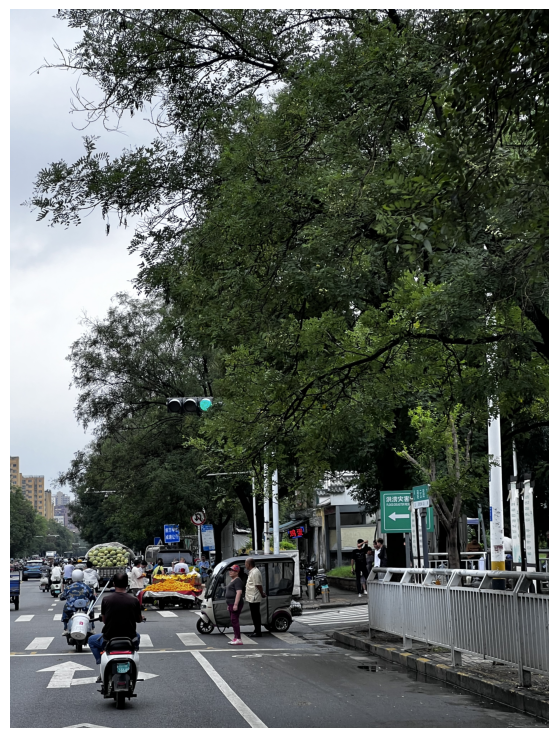

(a) → fig_a.pdf / fig_a.png


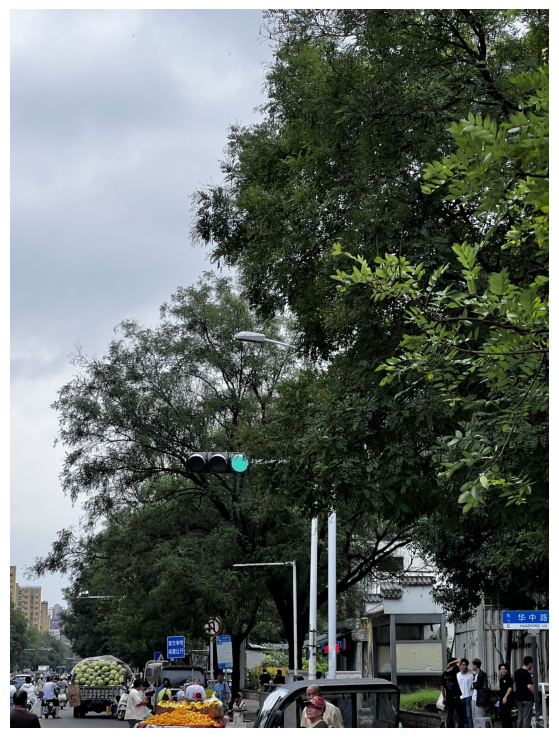

(b) → fig_b.pdf / fig_b.png


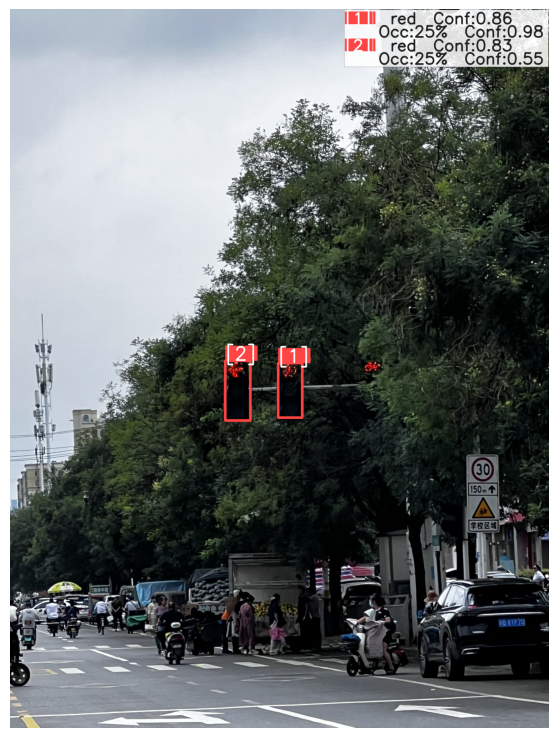

(c) → fig_c.pdf / fig_c.png


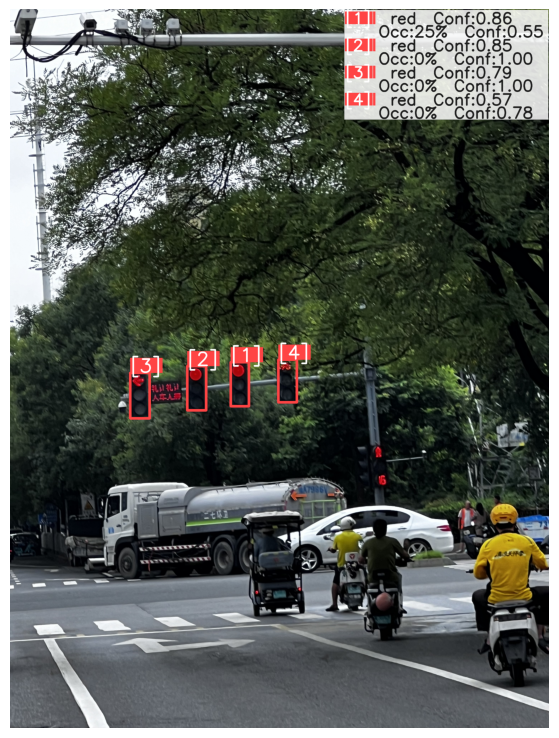

(d) → fig_d.pdf / fig_d.png


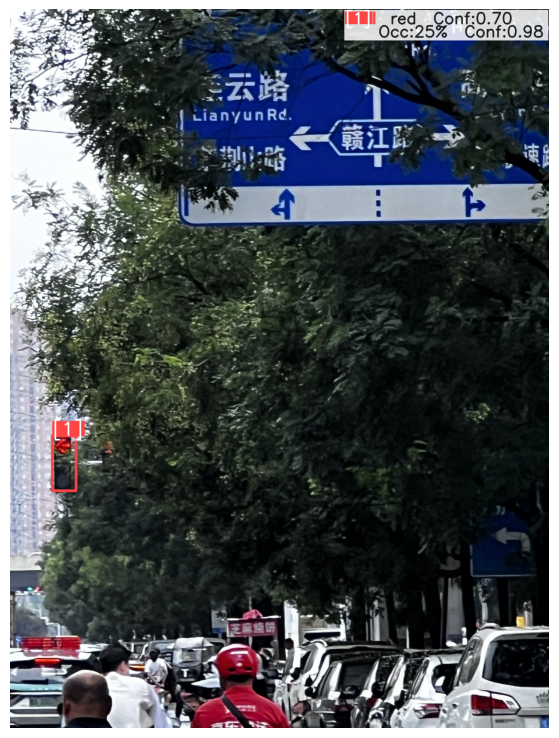

(e) → fig_e.pdf / fig_e.png


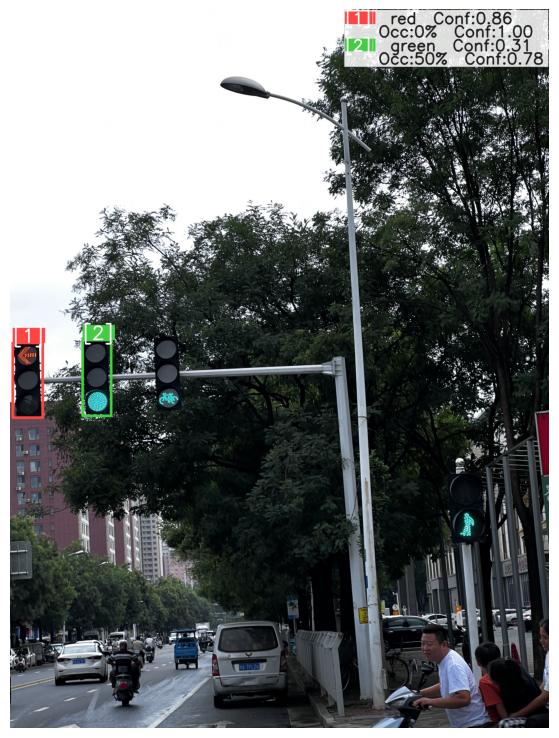

(f) → fig_f.pdf / fig_f.png


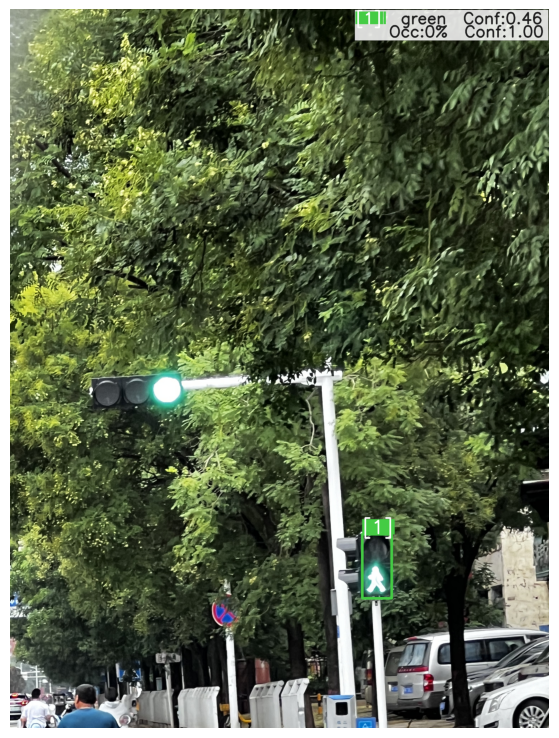

(g) → fig_g.pdf / fig_g.png


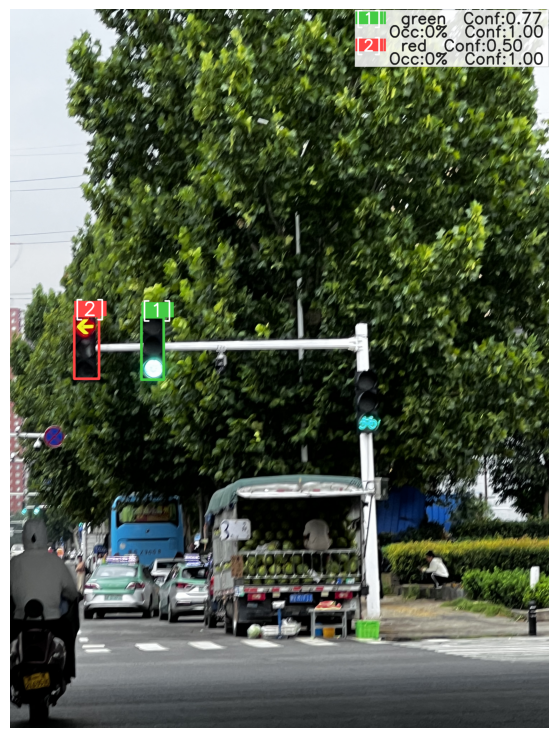

(h) → fig_h.pdf / fig_h.png


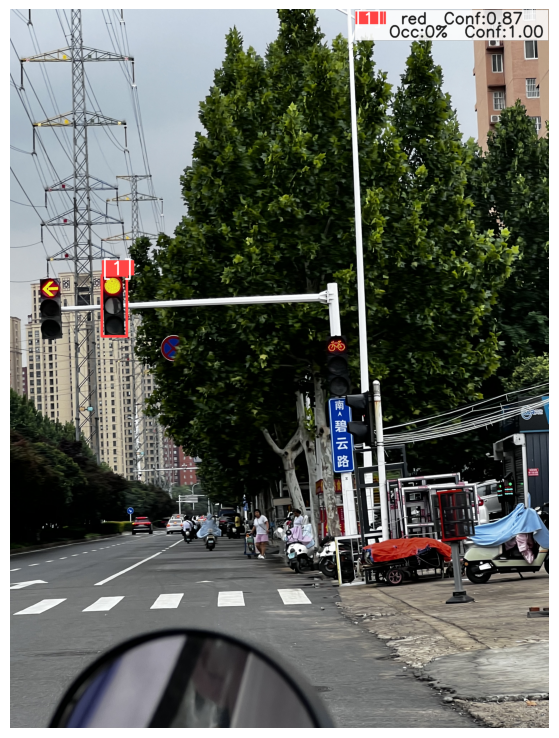

(i) → fig_i.pdf / fig_i.png


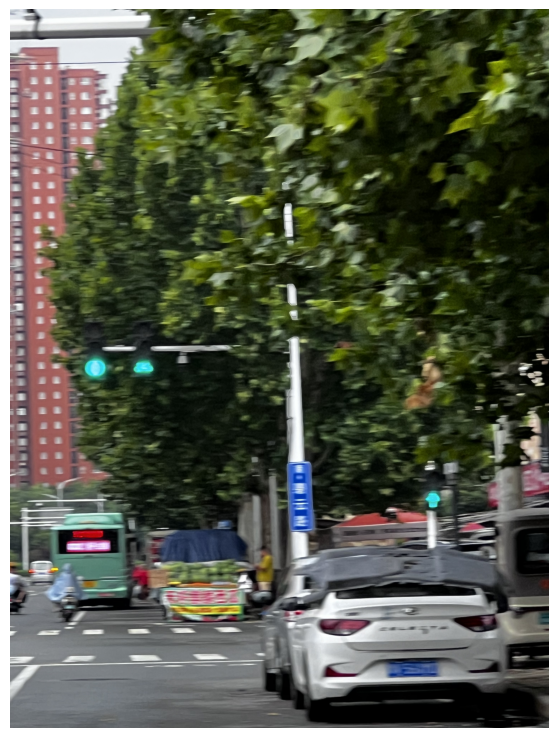

(j) → fig_j.pdf / fig_j.png


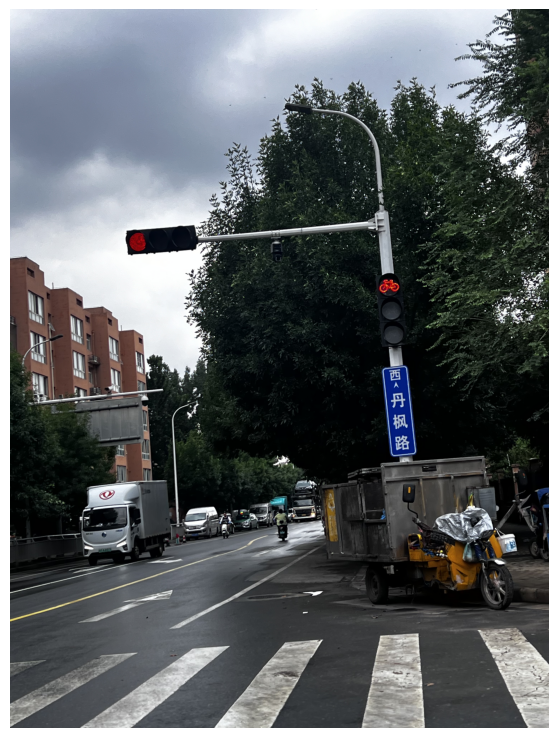

(k) → fig_k.pdf / fig_k.png


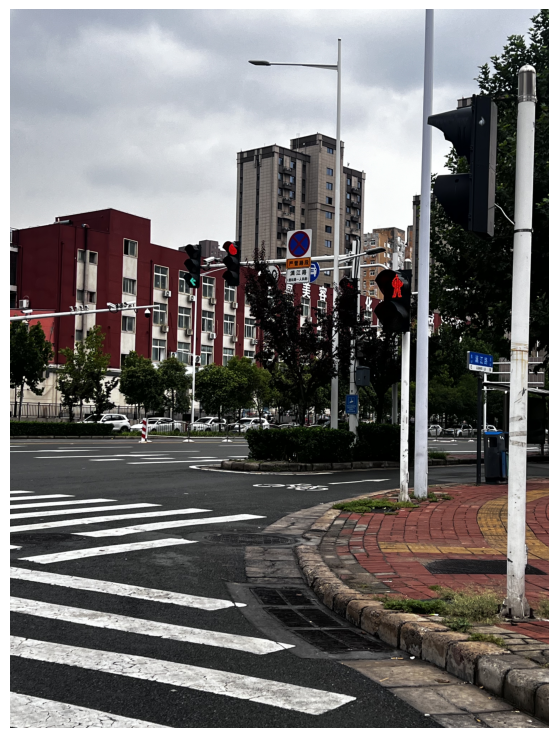

(l) → fig_l.pdf / fig_l.png


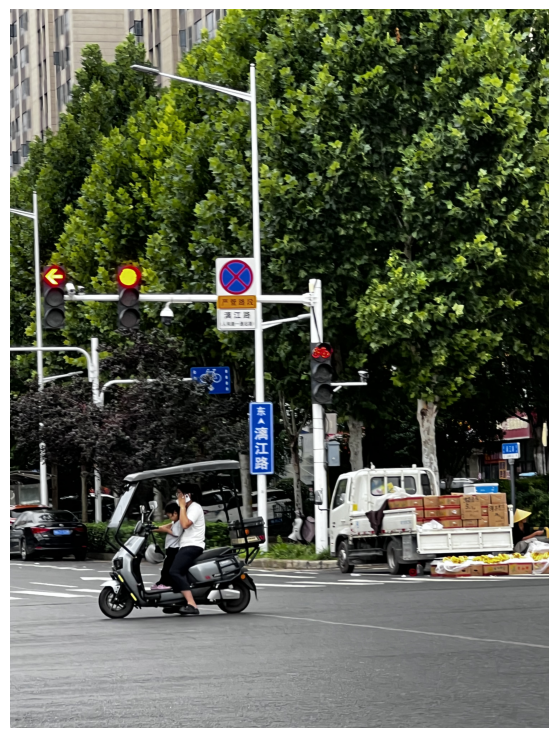

(m) → fig_m.pdf / fig_m.png


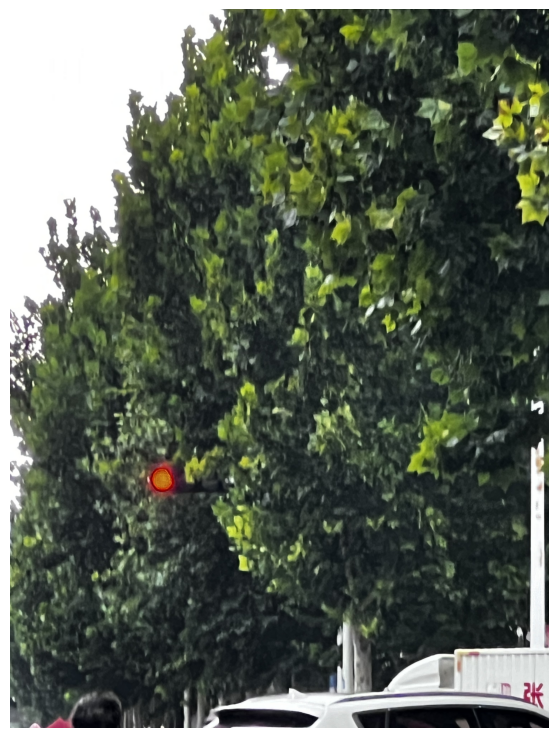

(n) → fig_n.pdf / fig_n.png


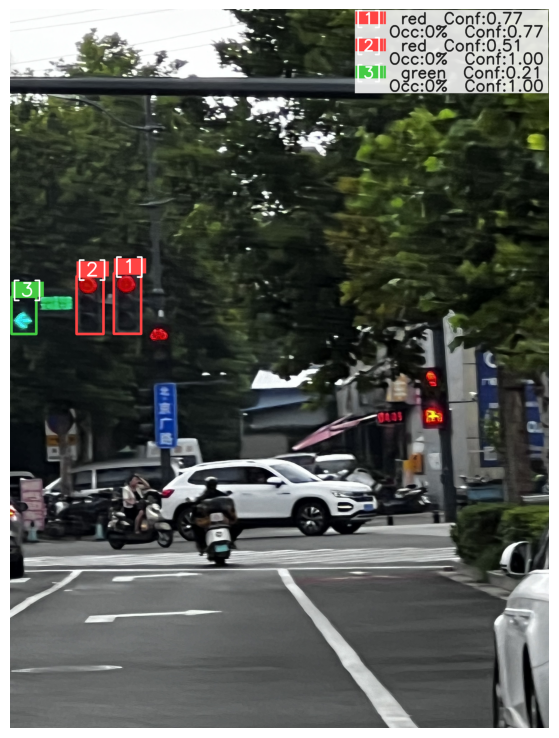

(o) → fig_o.pdf / fig_o.png


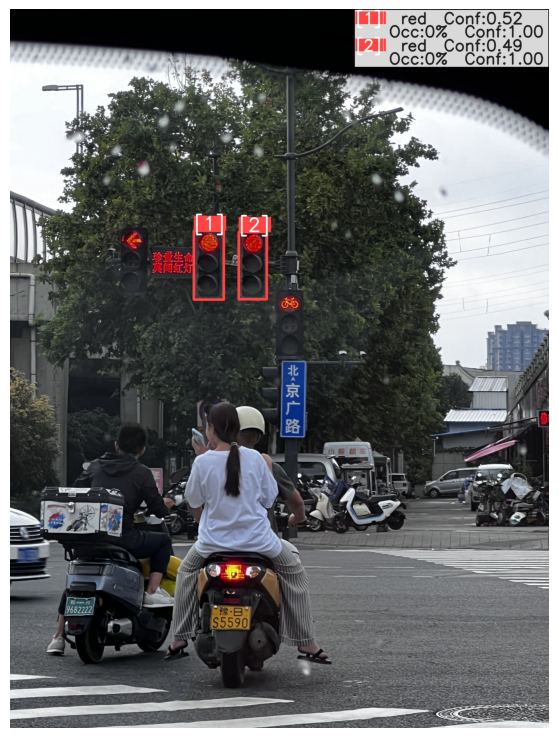

(p) → fig_p.pdf / fig_p.png


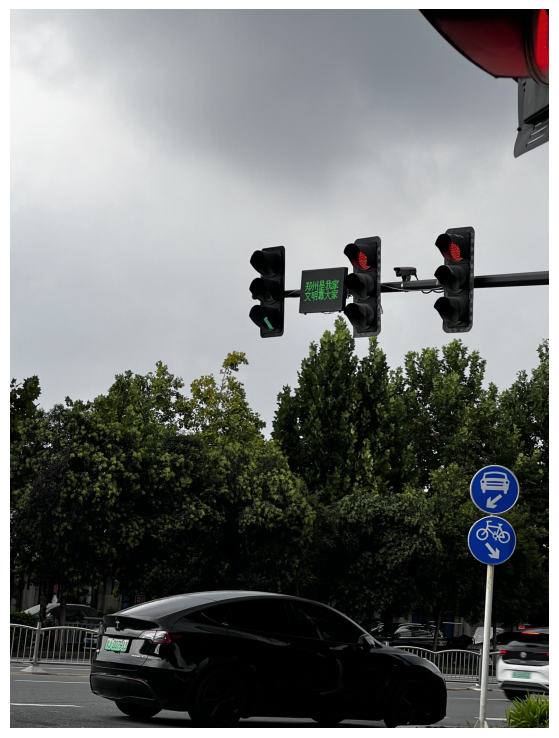

(q) → fig_q.pdf / fig_q.png


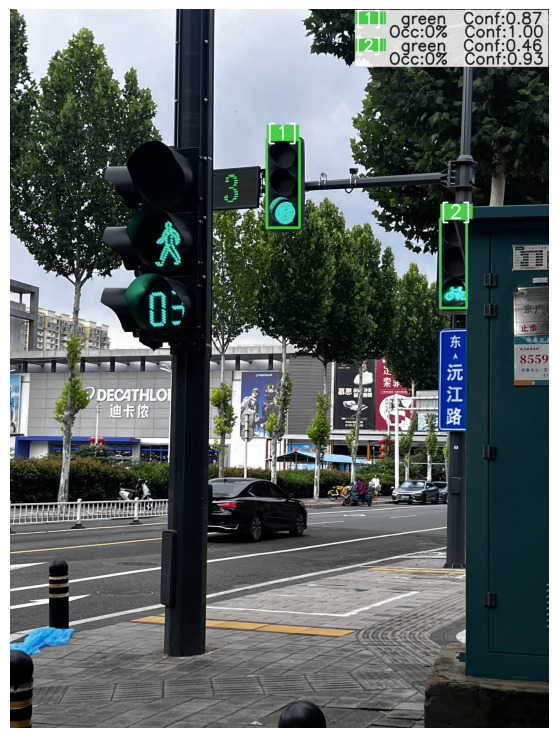

(r) → fig_r.pdf / fig_r.png


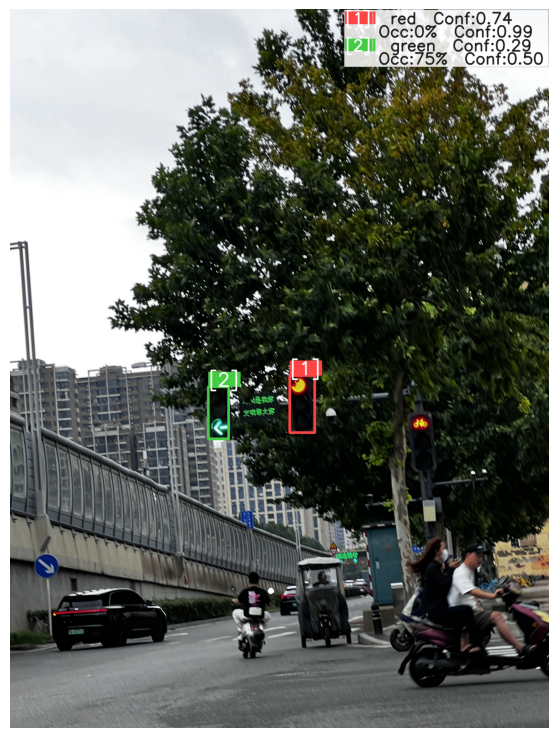

(s) → fig_s.pdf / fig_s.png

合計 19 枚の図を生成しました


In [ ]:
import matplotlib
matplotlib.rcParams['font.family'] = 'DejaVu Sans'
matplotlib.rcParams['font.size']   = 9

labels     = list('abcdefghijklmnopqrstuvwxyz')
num_labels = ['[1]','[2]','[3]','[4]','[5]','[6]','[7]','[8]']

for i, res in enumerate(all_results):
    H, W = res['img_rgb'].shape[:2]
    fig, ax = plt.subplots(figsize=(7, 7 * H / W))
    ax.imshow(res['annotated'])   # RGB配列をそのまま表示
    ax.axis('off')

    dets = res['detections']
    if dets:
        parts = []
        for j, d in enumerate(dets):
            num     = num_labels[j] if j < len(num_labels) else f'[{j+1}]'
            occ_pct = d['occ_class'].split('%')[0] + '%'
            parts.append(
                f"{num} Signal:{d['signal']} Conf:{d['signal_conf']:.2f}  "
                f"Occ:{occ_pct} Conf:{d['occ_conf']:.2f}"
            )
        ax.set_xlabel(' | '.join(parts), fontsize=8, labelpad=4)
    else:
        ax.set_xlabel('No traffic light detected', fontsize=8, labelpad=4)

    fig_pdf = f'{OUTPUT_DIR}/fig_{labels[i]}.pdf'
    fig_png = f'{OUTPUT_DIR}/fig_{labels[i]}.png'
    plt.savefig(fig_pdf, dpi=300, bbox_inches='tight', format='pdf')
    plt.savefig(fig_png, dpi=300, bbox_inches='tight', format='png')
    plt.show()
    plt.close()
    print(f'({labels[i]}) → fig_{labels[i]}.pdf / fig_{labels[i]}.png')

print(f'\n合計 {len(all_results)} 枚の図を生成しました')
